# How long does a signal stay in the detector band?

This notebook produces the figure that shows

* **left:** the time left before merger as a function of the gravitational-wave frequency;
* **right:** a sketch of how the sky localization of a source improves while the signal is still being recorded.

The left panel is a real calculation. The right panel is only a drawing: it is not the result of an analysis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from gwr_style import COLORS, TEXTWIDTH, save_figure

## Time to merger

At leading order, a binary whose gravitational-wave frequency is $f$ merges after a time

$$\tau(f) = \frac{5}{256}\left(\frac{G\mathcal{M}_d}{c^3}\right)^{-5/3}(\pi f)^{-8/3},$$

where $\mathcal{M}_d$ is the detector-frame chirp mass. The combination $G M_\odot/c^3$ is a time: about 4.9 microseconds.

In [2]:
# G * (one solar mass) / c^3, in seconds
G_MSUN_C3 = 4.925491e-6


def chirp_mass(m1, m2):
    """Chirp mass of a binary with component masses m1 and m2 (same units as the masses)."""
    return (m1 * m2) ** 0.6 / (m1 + m2) ** 0.2


def time_to_merger(f, mc):
    """Time left before merger, in seconds.

    f  : gravitational-wave frequency in Hz
    mc : chirp mass in solar masses
    """
    return 5.0 / 256.0 * (G_MSUN_C3 * mc) ** (-5.0 / 3.0) * (np.pi * f) ** (-8.0 / 3.0)


# A quick check: a binary neutron star (1.4 + 1.4 solar masses) at 20 Hz and at 3 Hz
mc_bns = chirp_mass(1.4, 1.4)
print(f"at 20 Hz: {time_to_merger(20, mc_bns):.0f} seconds")
print(f"at  3 Hz: {time_to_merger(3, mc_bns) / 3600:.1f} hours")

at 20 Hz: 158 seconds
at  3 Hz: 6.9 hours


## The figure

Figure saved to output/fig_signal_duration.pdf


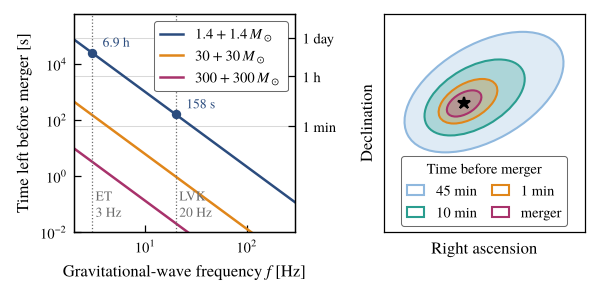

In [3]:
fig, (ax_left, ax_right) = plt.subplots(
    1, 2, figsize=(TEXTWIDTH, 0.43 * TEXTWIDTH), gridspec_kw={"width_ratios": [1.1, 1.0], "wspace": 0.42}
)

# ----- Left panel: time to merger for three equal-mass binaries -----
frequencies = np.geomspace(2, 300, 400)
systems = [
    (r"$1.4+1.4\,M_\odot$", chirp_mass(1.4, 1.4), COLORS["blue"]),
    (r"$30+30\,M_\odot$", chirp_mass(30, 30), COLORS["orange"]),
    (r"$300+300\,M_\odot$", chirp_mass(300, 300), COLORS["magenta"]),
]
for label, mc, color in systems:
    ax_left.loglog(frequencies, time_to_merger(frequencies, mc), color=color, label=label)

# Mark the lowest frequency that current (LVK) and future (ET) detectors can observe
for f_low, name in [(3, "ET"), (20, "LVK")]:
    ax_left.axvline(f_low, color=COLORS["grey"], lw=0.6, ls=":")
    ax_left.text(f_low * 1.08, 2.5e-2, f"{name}\n{f_low} Hz", fontsize=6.5, color=COLORS["grey"], va="bottom")
    tau = time_to_merger(f_low, mc_bns)
    ax_left.plot(f_low, tau, "o", ms=3.5, color=COLORS["blue"])
    text = f"{tau / 3600:.1f} h" if tau > 3600 else f"{tau:.0f} s"
    # write the value next to the point
    ax_left.annotate(text, (f_low, tau), xytext=(5, 3), textcoords="offset points", ha="left",
                     fontsize=6.5, color=COLORS["blue"])

# Horizontal guide lines at one minute, one hour and one day
for seconds in (60, 3600, 86400):
    ax_left.axhline(seconds, color=COLORS["lightgrey"], lw=0.5, zorder=0)

ax_left.set_xlim(2, 300)
ax_left.set_ylim(1e-2, 6e5)
ax_left.set_xlabel("Gravitational-wave frequency $f$ [Hz]")
ax_left.set_ylabel("Time left before merger [s]")
ax_left.legend(loc="upper right", handlelength=1.6)

# A second vertical axis on the right, with the same scale but labelled in minutes, hours and days
ax_units = ax_left.twinx()
ax_units.set_yscale("log")
ax_units.set_ylim(ax_left.get_ylim())
ax_units.set_yticks([60, 3600, 86400])
ax_units.set_yticklabels(["1 min", "1 h", "1 day"])
ax_units.minorticks_off()

# ----- Right panel: a sketch of the sky localization shrinking with time -----
# Each ellipse is the region of the sky compatible with the data at a given time before merger.
# The sizes are chosen by hand.
stages = [
    ("45 min", 4.6, COLORS["lightblue"]),
    ("10 min", 2.9, COLORS["teal"]),
    ("1 min", 1.7, COLORS["orange"]),
    ("merger", 1.0, COLORS["magenta"]),
]
for name, size, color in stages:
    centre = (0.22 * (size - 1), 0.12 * (size - 1))
    # filled, transparent ellipse
    ax_right.add_patch(Ellipse(centre, 1.5 * size, 0.8 * size, angle=28, fc=color, ec="none", alpha=0.28))
    # outline of the same ellipse
    ax_right.add_patch(Ellipse(centre, 1.5 * size, 0.8 * size, angle=28, fc="none", ec=color, lw=1.0, label=name))

# The true position of the source
ax_right.plot(0, 0, marker="*", ms=6, color="k", ls="none")

ax_right.set_xlim(-3.2, 4.8)
ax_right.set_ylim(-4.9, 3.4)
ax_right.set_xticks([])
ax_right.set_yticks([])
ax_right.set_xlabel("Right ascension")
ax_right.set_ylabel("Declination")
ax_right.legend(title="Time before merger", title_fontsize=7, loc="lower center", ncol=2,
                handlelength=1.2, columnspacing=1.0, borderaxespad=0.4)

save_figure(fig, "fig_signal_duration.pdf")
plt.show()